# Comprehensive Exploratory Data Analysis (EDA) & Model Visualizations
## Fake Product Review Detection Using Classical Machine Learning & Sentiment Analysis


In [23]:
import os
import sys
import shutil
from pathlib import Path

# Ensure project root is in sys.path and set working directory
project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
os.chdir(project_root)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer

from src.data_loader import load_cleaned_primary_dataset, load_salminen_dataset
from src.preprocessing import (
    clean_text_raw, clean_text_light, clean_text_standard, 
    clean_text_lemmatized, extract_linguistic_features
)
from src.sentiment_analysis import VADERSentimentAnalyzer

# Output directories for saving PNG figures
FIG_DIR = Path('results/figures')
METRICS_DIR = Path('results/metrics')
FIG_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'figure.autolayout': True
})

def save_figure(fig, filename):
    """Helper to save PNG figures into both results/figures/ and results/metrics/"""
    p1 = FIG_DIR / filename
    p2 = METRICS_DIR / filename
    fig.savefig(p1, dpi=300, bbox_inches='tight')
    fig.savefig(p2, dpi=300, bbox_inches='tight')
    print(f'Saved: {p1} and {p2}')

print(f'Working directory: {os.getcwd()}')
print('Setup complete. All modules and paths ready!')

Working directory: e:\ML\mini project 2
Setup complete. All modules and paths ready!


## 1. Data Ingestion via Unified 12-Column Schema
Load both the Primary ground-truth fraud campaign dataset (**He et al., 2022**) and the Secondary cross-domain AI review benchmark (**Salminen et al., 2022**).

In [24]:
df_primary = load_cleaned_primary_dataset()
print(f'Primary Dataset (He et al.): {df_primary.shape[0]:,} rows, {df_primary.shape[1]} columns')

df_salminen = load_salminen_dataset()
print(f'Secondary Dataset (Salminen et al.): {df_salminen.shape[0]:,} rows, {df_salminen.shape[1]} columns')

display(df_primary.head(3))

Primary Dataset (He et al.): 32,940 rows, 12 columns
Secondary Dataset (Salminen et al.): 40,432 rows, 12 columns


,review_id,reviewer_id,product_id,product_category,review_title,review_text,rating,verified_purchase,timestamp,label,original_label,source_dataset
0,R36G7QSYO7QRAS,AFP3AD7L3KWYHHQ4UQAIWJAZX7FQ,NaN,Amazon Products (Unspecified),Cut pvc like fruit.,", Your browser does not support HTML5 video...",NaN,NaN,NaN,1,1,He_et_al_Amazon_Cleaned
1,R1CM6Y3BKQGPSE,AH74ZCS65PTXJHOWW46XQUKY46GA,NaN,Amazon Products (Unspecified),Super easy to use,Got this to cut the pipe behind toilet that wa...,NaN,NaN,NaN,1,1,He_et_al_Amazon_Cleaned
2,R3LVQ4CXB7F53U,AFJEFSALLQGG3EU3MQTHYE2Y4RRA,NaN,Amazon Products (Unspecified),Good quality,Light is very well packaged to protect it du...,NaN,NaN,NaN,1,1,He_et_al_Amazon_Cleaned


## 2. Class Distributions & Figure 1
Generate and save **Figure 1: Class Distribution Comparison** (`01_class_distribution_comparison.png`).

Saved: results\figures\01_class_distribution_comparison.png and results\metrics\01_class_distribution_comparison.png


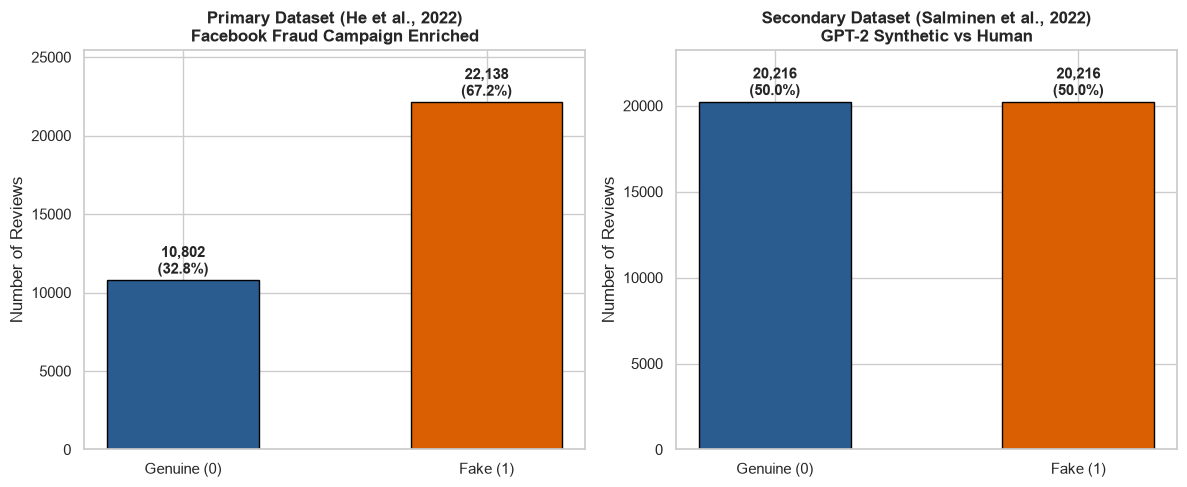

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colors = ['#2b5c8f', '#d95f02']

# Primary Dataset (He et al.)
cnt1 = df_primary['label'].value_counts().sort_index()
bars1 = axes[0].bar(['Genuine (0)', 'Fake (1)'], cnt1.values, color=colors, edgecolor='black', width=0.5)
axes[0].set_title('Primary Dataset (He et al., 2022)\nFacebook Fraud Campaign Enriched', fontweight='bold')
axes[0].set_ylabel('Number of Reviews')
axes[0].set_ylim(0, max(cnt1.values) * 1.15)
for b in bars1:
    y = b.get_height()
    axes[0].text(b.get_x() + b.get_width()/2, y + 400, f'{y:,}\n({y/len(df_primary):.1%})', ha='center', fontweight='bold')

# Secondary Dataset (Salminen et al.)
cnt2 = df_salminen['label'].value_counts().sort_index()
bars2 = axes[1].bar(['Genuine (0)', 'Fake (1)'], cnt2.values, color=colors, edgecolor='black', width=0.5)
axes[1].set_title('Secondary Dataset (Salminen et al., 2022)\nGPT-2 Synthetic vs Human', fontweight='bold')
axes[1].set_ylabel('Number of Reviews')
axes[1].set_ylim(0, max(cnt2.values) * 1.15)
for b in bars2:
    y = b.get_height()
    axes[1].text(b.get_x() + b.get_width()/2, y + 400, f'{y:,}\n({y/len(df_salminen):.1%})', ha='center', fontweight='bold')

save_figure(fig, '01_class_distribution_comparison.png')
plt.show()

## 3. Review Length Density & Figure 2
Generate and save **Figure 2: Review Length Distributions** (`02_review_length_distribution.png`).

Saved: results\figures\02_review_length_distribution.png and results\metrics\02_review_length_distribution.png


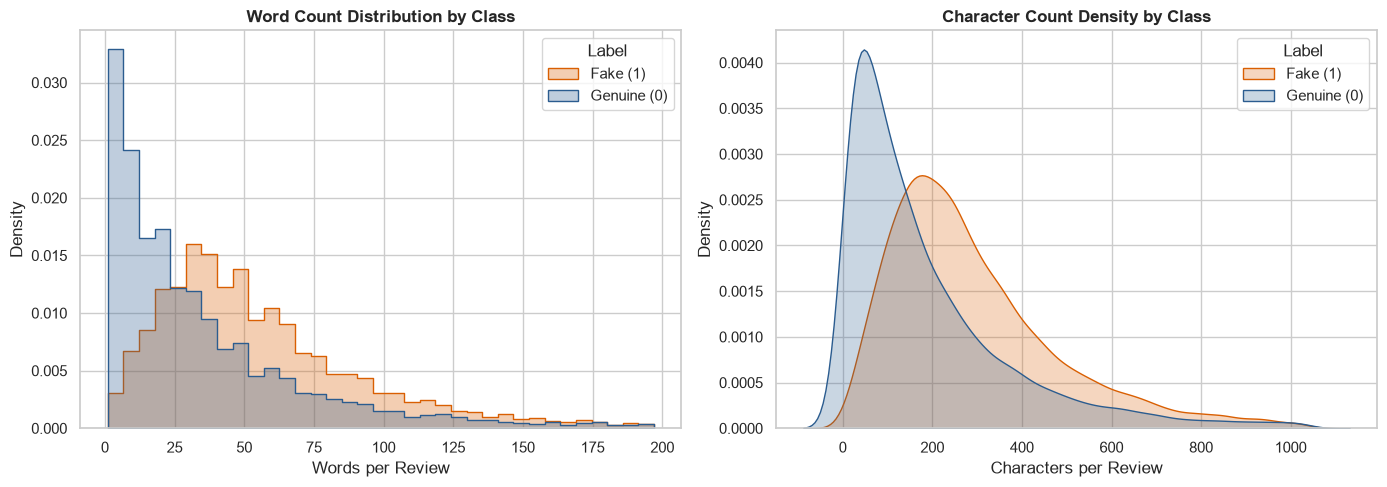

In [26]:
df_primary['word_count'] = df_primary['review_text'].apply(lambda t: len(str(t).split()))
df_primary['char_count'] = df_primary['review_text'].apply(lambda t: len(str(t)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cap_words = np.percentile(df_primary['word_count'], 98)
filtered = df_primary[df_primary['word_count'] <= cap_words]

# Word Count Density
sns.histplot(
    data=filtered, x='word_count', hue='label', element='step', stat='density',
    common_norm=False, palette={0: '#2b5c8f', 1: '#d95f02'}, ax=axes[0], bins=35, alpha=0.3
)
axes[0].set_title('Word Count Distribution by Class', fontweight='bold')
axes[0].set_xlabel('Words per Review')
axes[0].legend(title='Label', labels=['Fake (1)', 'Genuine (0)'])

# Character Count Density
cap_chars = np.percentile(df_primary['char_count'], 98)
filtered_chars = df_primary[df_primary['char_count'] <= cap_chars]
sns.kdeplot(
    data=filtered_chars, x='char_count', hue='label', common_norm=False,
    palette={0: '#2b5c8f', 1: '#d95f02'}, ax=axes[1], fill=True, alpha=0.25
)
axes[1].set_title('Character Count Density by Class', fontweight='bold')
axes[1].set_xlabel('Characters per Review')
axes[1].legend(title='Label', labels=['Fake (1)', 'Genuine (0)'])

save_figure(fig, '02_review_length_distribution.png')
plt.show()

## 4. Review Length Boxplots & Figure 3
Generate and save **Figure 3: Review Length Boxplots** (`03_review_length_boxplots.png`).  
*Notice: Fake reviews are on average 2x longer (median 48 words vs 24 words).*

Saved: results\figures\03_review_length_boxplots.png and results\metrics\03_review_length_boxplots.png


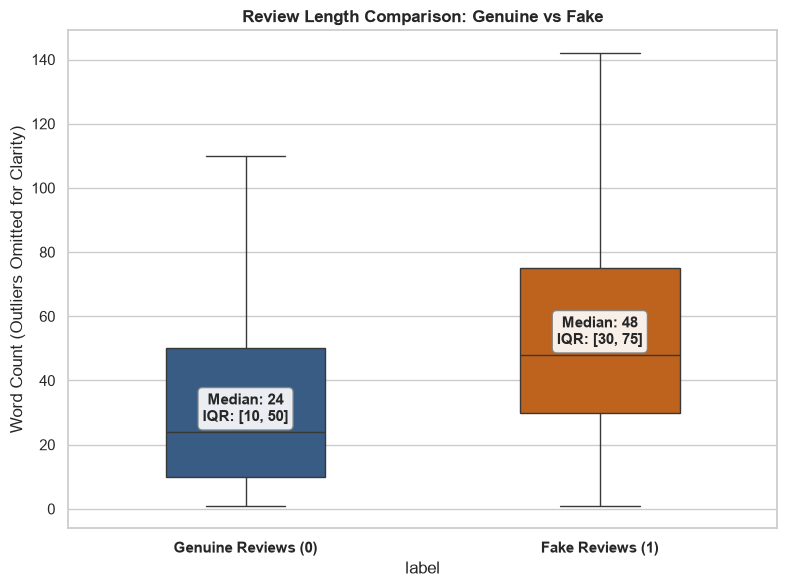

In [27]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(
    data=df_primary, x='label', y='word_count', hue='label',
    palette=['#2b5c8f', '#d95f02'], showfliers=False, width=0.45, legend=False, ax=ax
)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Genuine Reviews (0)', 'Fake Reviews (1)'], fontweight='bold')
ax.set_ylabel('Word Count (Outliers Omitted for Clarity)')
ax.set_title('Review Length Comparison: Genuine vs Fake', fontweight='bold')

for i, l in enumerate([0, 1]):
    sub = df_primary[df_primary['label'] == l]['word_count']
    med, q25, q75 = sub.median(), sub.quantile(0.25), sub.quantile(0.75)
    ax.text(i, med + 2, f'Median: {med:.0f}\nIQR: [{q25:.0f}, {q75:.0f}]',
            ha='center', va='bottom', fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='gray', alpha=0.9))

save_figure(fig, '03_review_length_boxplots.png')
plt.show()

## 5. Star Rating Distribution by Authenticity & Figure 4
Generate and save **Figure 4: Rating Distribution by Label** (`04_rating_distribution_by_label.png`).

Saved: results\figures\04_rating_distribution_by_label.png and results\metrics\04_rating_distribution_by_label.png


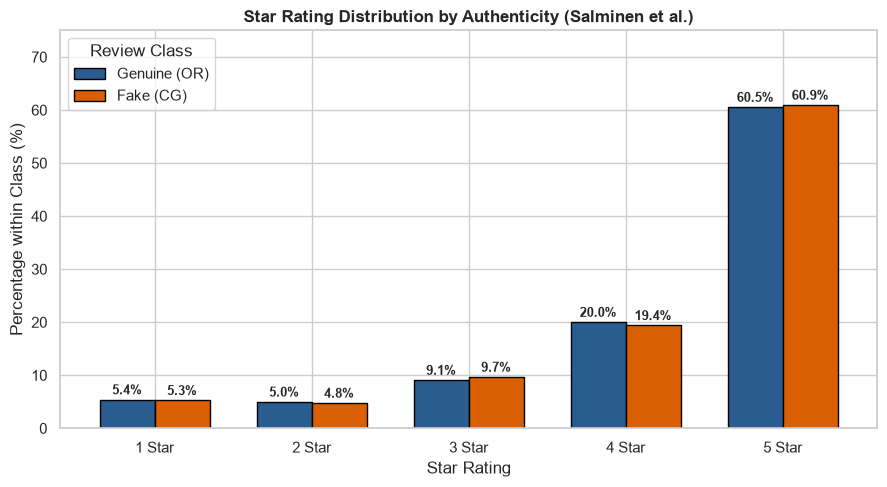

In [28]:
fig, ax = plt.subplots(figsize=(9, 5))
cross = pd.crosstab(df_salminen['rating'], df_salminen['label'], normalize='columns') * 100
cross.columns = ['Genuine (OR)', 'Fake (CG)']

cross.plot(kind='bar', ax=ax, color=['#2b5c8f', '#d95f02'], edgecolor='black', width=0.7)
ax.set_title('Star Rating Distribution by Authenticity (Salminen et al.)', fontweight='bold')
ax.set_xlabel('Star Rating')
ax.set_ylabel('Percentage within Class (%)')
ax.set_xticklabels([f'{int(r)} Star' for r in cross.index], rotation=0)
ax.set_ylim(0, 75)
ax.legend(title='Review Class')

for p in ax.patches:
    h = p.get_height()
    if h > 1.0:
        ax.annotate(f'{h:.1f}%', (p.get_x() + p.get_width()/2., h + 1.0), ha='center', fontsize=9, fontweight='bold')

save_figure(fig, '04_rating_distribution_by_label.png')
plt.show()

## 6. Top Bigrams Comparison & Figure 5
Generate and save **Figure 5: Top Words / Bigrams in Genuine vs Fake** (`05_top_words_genuine_vs_fake.png`).

Saved: results\figures\05_top_words_genuine_vs_fake.png and results\metrics\05_top_words_genuine_vs_fake.png


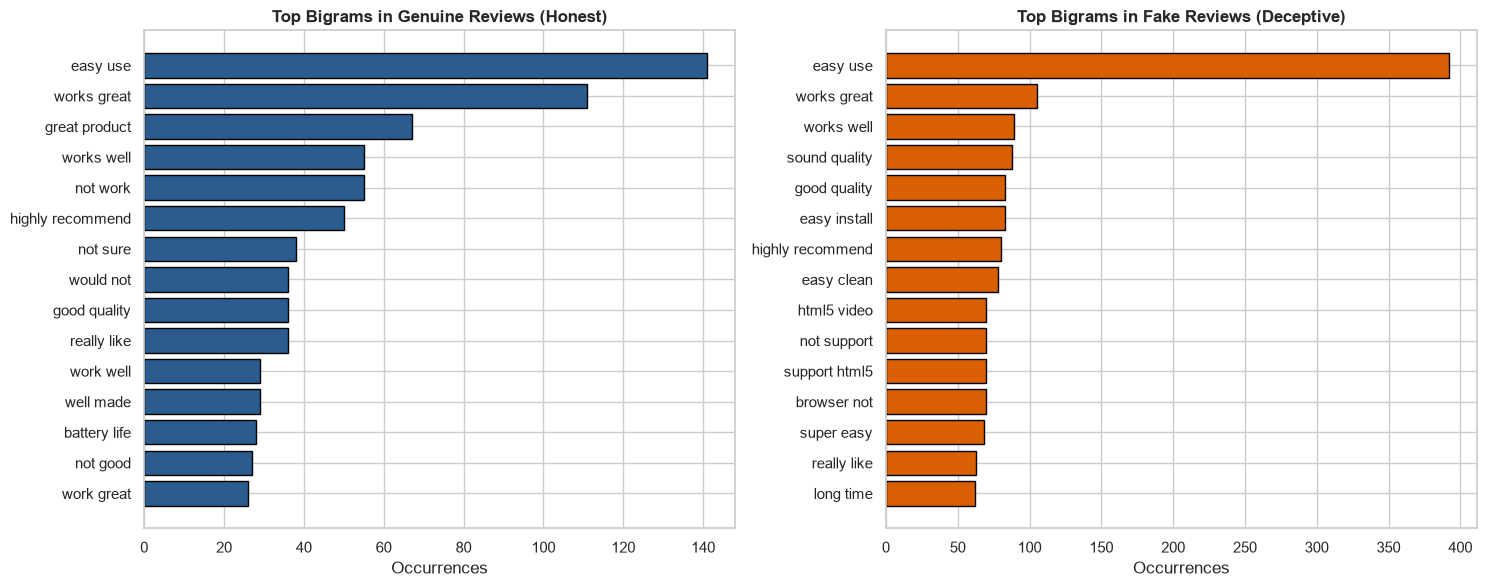

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for idx, (l, title, col) in enumerate([
    (0, 'Genuine Reviews (Honest)', '#2b5c8f'),
    (1, 'Fake Reviews (Deceptive)', '#d95f02')
]):
    sub_texts = df_primary[df_primary['label'] == l]['review_text'].head(3000).apply(
        lambda t: clean_text_standard(str(t), preserve_negations=True)
    )
    vec = CountVectorizer(ngram_range=(2, 2), max_features=15)
    mat = vec.fit_transform(sub_texts)
    cnts = mat.sum(axis=0).A1
    words = vec.get_feature_names_out()
    ngram_df = pd.DataFrame({'bigram': words, 'frequency': cnts}).sort_values('frequency', ascending=True)

    axes[idx].barh(ngram_df['bigram'], ngram_df['frequency'], color=col, edgecolor='black')
    axes[idx].set_title(f'Top Bigrams in {title}', fontweight='bold')
    axes[idx].set_xlabel('Occurrences')

save_figure(fig, '05_top_words_genuine_vs_fake.png')
plt.show()

## 7. Product Category Breakdown & Figure 6
Generate and save **Figure 6: Category Distribution** (`06_category_distribution_by_label.png`).

C:\Users\Tauqeer Rizvi\AppData\Local\Temp\ipykernel_29836\1194712478.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_salminen, y='product_category', order=order, palette='crest', edgecolor='black', ax=ax)


Saved: results\figures\06_category_distribution_by_label.png and results\metrics\06_category_distribution_by_label.png


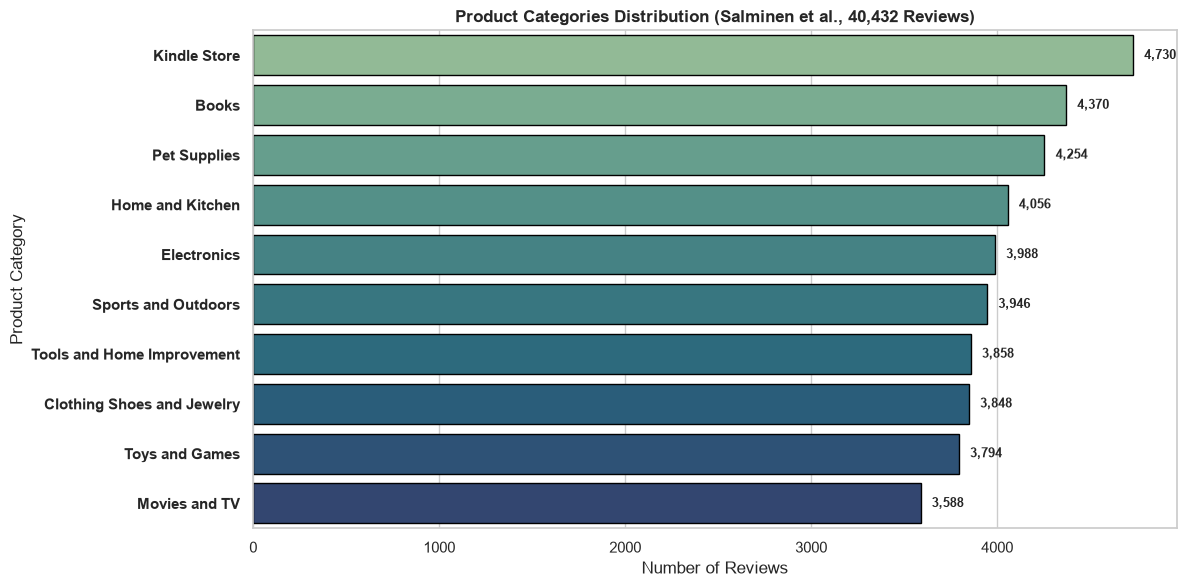

In [30]:
fig, ax = plt.subplots(figsize=(12, 6))
order = df_salminen['product_category'].value_counts().index
clean_labels = [c.replace('_5', '').replace('_', ' ') for c in order]

sns.countplot(data=df_salminen, y='product_category', order=order, palette='crest', edgecolor='black', ax=ax)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(clean_labels, fontweight='bold')
ax.set_title('Product Categories Distribution (Salminen et al., 40,432 Reviews)', fontweight='bold')
ax.set_xlabel('Number of Reviews')
ax.set_ylabel('Product Category')

for p in ax.patches:
    w = p.get_width()
    ax.annotate(f'{int(w):,}', (w + 60, p.get_y() + p.get_height()/2.), va='center', fontsize=9, fontweight='bold')

save_figure(fig, '06_category_distribution_by_label.png')
plt.show()

## 8. Stylometric Linguistic Markers & Figure 7
Generate and save **Figure 7: Linguistic Markers Comparison** (`07_linguistic_markers_comparison.png`).

Saved: results\figures\07_linguistic_markers_comparison.png and results\metrics\07_linguistic_markers_comparison.png


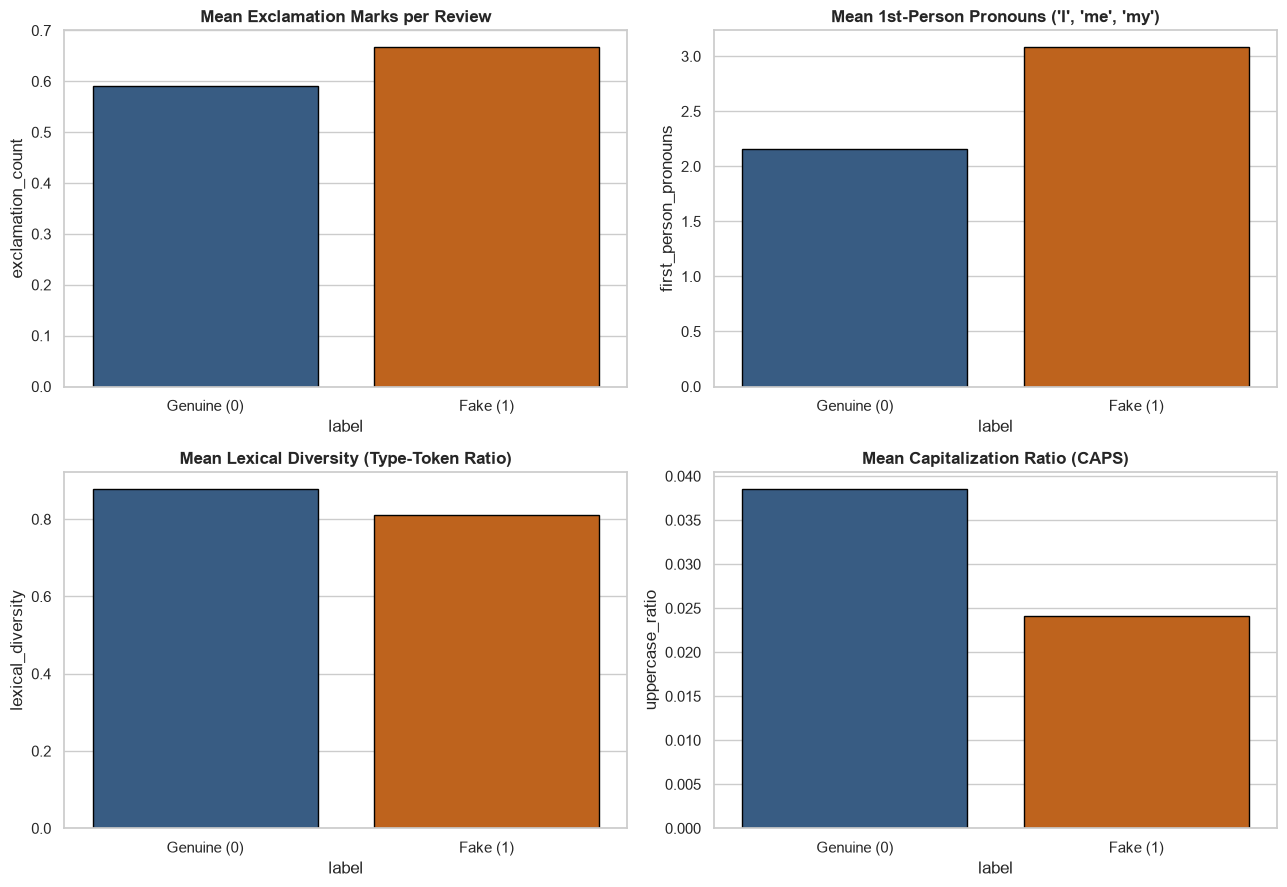

In [31]:
sample_df = df_primary.sample(min(2000, len(df_primary)), random_state=42).copy()
feats_list = sample_df['review_text'].apply(extract_linguistic_features).tolist()
feat_df = pd.DataFrame(feats_list)
feat_df['label'] = sample_df['label'].values

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
cols = ['#2b5c8f', '#d95f02']

# Exclamation Count
sns.barplot(data=feat_df, x='label', y='exclamation_count', hue='label', palette=cols, ax=axes[0,0], errorbar=None, edgecolor='black', legend=False)
axes[0,0].set_title('Mean Exclamation Marks per Review', fontweight='bold')
axes[0,0].set_xticks([0, 1])
axes[0,0].set_xticklabels(['Genuine (0)', 'Fake (1)'])

# 1st Person Pronouns
sns.barplot(data=feat_df, x='label', y='first_person_pronouns', hue='label', palette=cols, ax=axes[0,1], errorbar=None, edgecolor='black', legend=False)
axes[0,1].set_title("Mean 1st-Person Pronouns ('I', 'me', 'my')", fontweight='bold')
axes[0,1].set_xticks([0, 1])
axes[0,1].set_xticklabels(['Genuine (0)', 'Fake (1)'])

# Lexical Diversity (TTR)
sns.barplot(data=feat_df, x='label', y='lexical_diversity', hue='label', palette=cols, ax=axes[1,0], errorbar=None, edgecolor='black', legend=False)
axes[1,0].set_title('Mean Lexical Diversity (Type-Token Ratio)', fontweight='bold')
axes[1,0].set_xticks([0, 1])
axes[1,0].set_xticklabels(['Genuine (0)', 'Fake (1)'])

# Uppercase Ratio
sns.barplot(data=feat_df, x='label', y='uppercase_ratio', hue='label', palette=cols, ax=axes[1,1], errorbar=None, edgecolor='black', legend=False)
axes[1,1].set_title('Mean Capitalization Ratio (CAPS)', fontweight='bold')
axes[1,1].set_xticks([0, 1])
axes[1,1].set_xticklabels(['Genuine (0)', 'Fake (1)'])

save_figure(fig, '07_linguistic_markers_comparison.png')
plt.show()

## 9. VADER Sentiment Polarity Distribution & Figure 8
Generate and save **Figure 8: Sentiment Distribution by Class** (`08_sentiment_distribution_by_class.png`).

Saved: results\figures\08_sentiment_distribution_by_class.png and results\metrics\08_sentiment_distribution_by_class.png


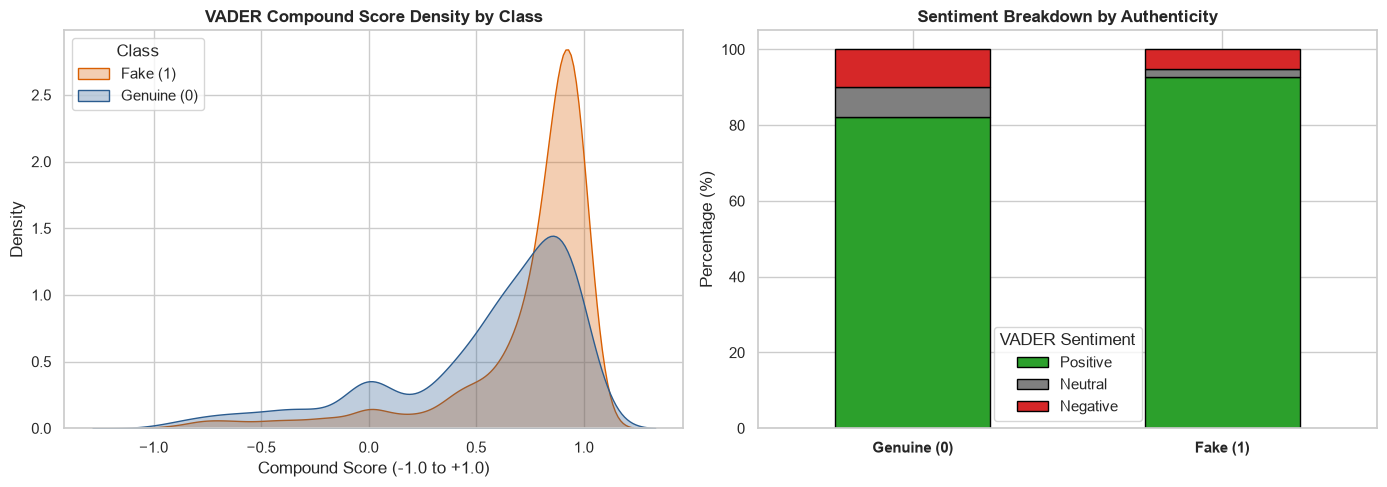

In [32]:
analyzer = VADERSentimentAnalyzer()
sample_sent = df_primary.sample(min(3000, len(df_primary)), random_state=42).copy()
sent_records = sample_sent['review_text'].apply(analyzer.analyze).tolist()
sent_df = pd.DataFrame(sent_records)
sample_sent['compound'] = sent_df['compound'].values
sample_sent['sentiment_label'] = sent_df['sentiment_label'].values

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Compound Density
sns.kdeplot(data=sample_sent, x='compound', hue='label', palette={0: '#2b5c8f', 1: '#d95f02'}, fill=True, alpha=0.3, ax=axes[0], common_norm=False)
axes[0].set_title('VADER Compound Score Density by Class', fontweight='bold')
axes[0].set_xlabel('Compound Score (-1.0 to +1.0)')
axes[0].legend(title='Class', labels=['Fake (1)', 'Genuine (0)'])

# Plot 2: Categorical Proportions
ct = pd.crosstab(sample_sent['label'], sample_sent['sentiment_label'], normalize='index') * 100
ct = ct[['Positive', 'Neutral', 'Negative']]
ct.index = ['Genuine (0)', 'Fake (1)']
ct.plot(kind='bar', stacked=True, color=['#2ca02c', '#7f7f7f', '#d62728'], edgecolor='black', ax=axes[1], width=0.5)
axes[1].set_title('Sentiment Breakdown by Authenticity', fontweight='bold')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_xticklabels(ct.index, rotation=0, fontweight='bold')
axes[1].legend(title='VADER Sentiment')

save_figure(fig, '08_sentiment_distribution_by_class.png')
plt.show()

## 10. Copy and Verify All Figures in `results/metrics/`
Verify that all generated `.png` files are present in `results/metrics/`.

In [33]:
png_files = list(FIG_DIR.glob('*.png'))
for p in png_files:
    target = METRICS_DIR / p.name
    if not target.exists():
        shutil.copy(p, target)

metrics_pngs = sorted(list(METRICS_DIR.glob('*.png')))
print(f'Total .png figures confirmed in {METRICS_DIR}: {len(metrics_pngs)}')
for f in metrics_pngs:
    print(f' - {f.name} ({f.stat().st_size / 1024:.1f} KB)')

Total .png figures confirmed in results\metrics: 13
 - 01_class_distribution_comparison.png (156.0 KB)
 - 02_review_length_distribution.png (241.0 KB)
 - 03_review_length_boxplots.png (114.9 KB)
 - 04_rating_distribution_by_label.png (132.7 KB)
 - 05_top_words_genuine_vs_fake.png (237.8 KB)
 - 06_category_distribution_by_label.png (163.8 KB)
 - 07_linguistic_markers_comparison.png (235.7 KB)
 - 08_sentiment_distribution_by_class.png (222.2 KB)
 - 09_roc_pr_curves.png (684.4 KB)
 - 10_confusion_matrices_comparison.png (264.8 KB)
 - 11_threshold_tuning_curve.png (252.1 KB)
 - 12_top_feature_coefficients.png (216.6 KB)
 - 13_cross_domain_category_performance.png (241.2 KB)
